## Practical - 01 Study and implementation of Python libraries used in Machine Learning such as NumPy, Pandas,
and Matplotlib for data analysis and visualization.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
def hard_computing(temperature):
    if temperature >= 30:
        return "HOT"
    else:
        return "NORMAL"

temperatures = [20, 25, 28, 30, 32, 35, 40]

print("HARD COMPUTING RESULTS")
for temp in temperatures:
    print(f"Temperature: {temp}°C -> {hard_computing(temp)}")

HARD COMPUTING RESULTS
Temperature: 20°C -> NORMAL
Temperature: 25°C -> NORMAL
Temperature: 28°C -> NORMAL
Temperature: 30°C -> HOT
Temperature: 32°C -> HOT
Temperature: 35°C -> HOT
Temperature: 40°C -> HOT


In [4]:
def fuzzy_temperature(temp):
    if temp <= 20:
        return 0.0
    elif temp <= 30:
        return (temp - 20) / 10
    else:
        return 1.0

print("SOFT COMPUTING RESULTS")
for temp in temperatures:
    membership = fuzzy_temperature(temp)
    print(f"Temperature: {temp}°C -> Hot Membership: {membership:.2f}")

SOFT COMPUTING RESULTS
Temperature: 20°C -> Hot Membership: 0.00
Temperature: 25°C -> Hot Membership: 0.50
Temperature: 28°C -> Hot Membership: 0.80
Temperature: 30°C -> Hot Membership: 1.00
Temperature: 32°C -> Hot Membership: 1.00
Temperature: 35°C -> Hot Membership: 1.00
Temperature: 40°C -> Hot Membership: 1.00


In [5]:
hard_results = []
soft_results = []

for temp in temperatures:
    hard_results.append(1 if hard_computing(temp) == "HOT" else 0)
    soft_results.append(fuzzy_temperature(temp))

print("Temperature | Hard Computing | Soft Computing")
print("-----------------------------------------------")

for i, temp in enumerate(temperatures):
    print(f"{temp}°C         | {hard_results[i]}               | {soft_results[i]:.2f}")

Temperature | Hard Computing | Soft Computing
-----------------------------------------------
20°C         | 0               | 0.00
25°C         | 0               | 0.50
28°C         | 0               | 0.80
30°C         | 1               | 1.00
32°C         | 1               | 1.00
35°C         | 1               | 1.00
40°C         | 1               | 1.00


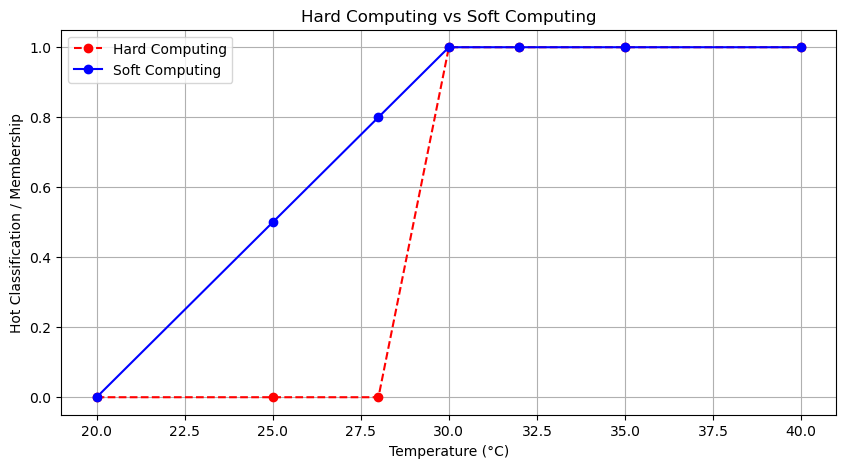

In [6]:
plt.figure(figsize=(10, 5))

plt.plot(temperatures, hard_results, 'ro--', label='Hard Computing')
plt.plot(temperatures, soft_results, 'bo-', label='Soft Computing')

plt.xlabel("Temperature (°C)")
plt.ylabel("Hot Classification / Membership")
plt.title("Hard Computing vs Soft Computing")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
def temperature_decision(temp):
    hot = fuzzy_temperature(temp)
    normal = 1 - hot

    if hot > normal:
        decision = "Turn ON Cooling"
    else:
        decision = "Cooling Not Required"

    return normal, hot, decision

print("APPROXIMATE REASONING RESULTS")

for temp in [22, 26, 29, 34, 38]:
    normal, hot, decision = temperature_decision(temp)

    print(f"\nTemperature: {temp}°C")
    print(f"Normal Membership: {normal:.2f}")
    print(f"Hot Membership: {hot:.2f}")
    print("Decision:", decision)

APPROXIMATE REASONING RESULTS

Temperature: 22°C
Normal Membership: 0.80
Hot Membership: 0.20
Decision: Cooling Not Required

Temperature: 26°C
Normal Membership: 0.40
Hot Membership: 0.60
Decision: Turn ON Cooling

Temperature: 29°C
Normal Membership: 0.10
Hot Membership: 0.90
Decision: Turn ON Cooling

Temperature: 34°C
Normal Membership: 0.00
Hot Membership: 1.00
Decision: Turn ON Cooling

Temperature: 38°C
Normal Membership: 0.00
Hot Membership: 1.00
Decision: Turn ON Cooling


## Practical -02 Implementation of the complete Machine Learning workflow including data loading, preprocessing,
model training, testing, and evaluation using scikit-learn.


In [9]:
import numpy as np
import matplotlib.pyplot as plt

In [10]:
A = {1, 2, 3, 4, 5}
B = {4, 5, 6, 7, 8}

print("Set A:", A)
print("Set B:", B)

print("Union:", A.union(B))
print("Intersection:", A.intersection(B))
print("Complement of A:", set(range(1, 9)) - A)

Set A: {1, 2, 3, 4, 5}
Set B: {4, 5, 6, 7, 8}
Union: {1, 2, 3, 4, 5, 6, 7, 8}
Intersection: {4, 5}
Complement of A: {8, 6, 7}


In [11]:
universe = np.array([1, 2, 3, 4, 5, 6, 7, 8])

A = np.array([0.1, 0.3, 0.5, 0.7, 0.9, 1.0, 0.6, 0.2])
B = np.array([0.8, 0.6, 0.4, 0.2, 0.3, 0.5, 0.7, 0.9])

print("Fuzzy Set A:", A)
print("Fuzzy Set B:", B)

Fuzzy Set A: [0.1 0.3 0.5 0.7 0.9 1.  0.6 0.2]
Fuzzy Set B: [0.8 0.6 0.4 0.2 0.3 0.5 0.7 0.9]


In [12]:
print("Commutative Law:")
print("A union B = B union A:",
      np.array_equal(np.maximum(A, B), np.maximum(B, A)))

print("A intersection B = B intersection A:",
      np.array_equal(np.minimum(A, B), np.minimum(B, A)))

print("\nIdempotent Law:")
print("A union A = A:",
      np.array_equal(np.maximum(A, A), A))

print("A intersection A = A:",
      np.array_equal(np.minimum(A, A), A))

print("\nComplement Law:")
print("A union complement A:",
      np.maximum(A, 1 - A))

print("A intersection complement A:",
      np.minimum(A, 1 - A))

Commutative Law:
A union B = B union A: True
A intersection B = B intersection A: True

Idempotent Law:
A union A = A: True
A intersection A = A: True

Complement Law:
A union complement A: [0.9 0.7 0.5 0.7 0.9 1.  0.6 0.8]
A intersection complement A: [0.1 0.3 0.5 0.3 0.1 0.  0.4 0.2]


NameError: name 'fuzzy_union' is not defined

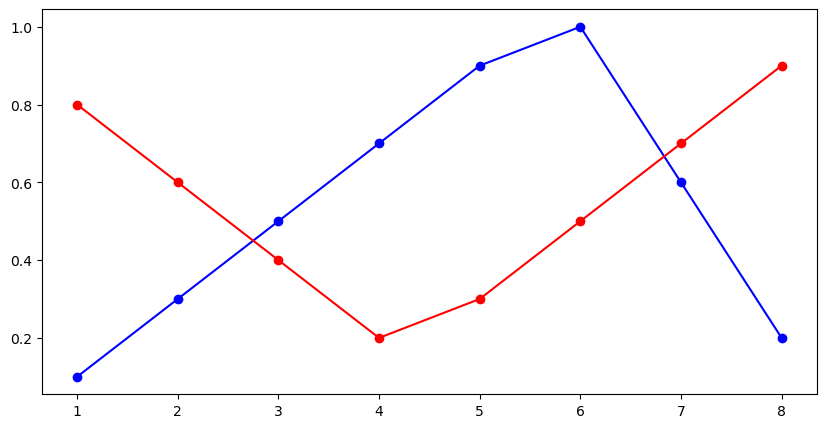

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(universe, A, 'bo-', label='Fuzzy Set A')
plt.plot(universe, B, 'ro-', label='Fuzzy Set B')
plt.plot(universe, fuzzy_union, 'g--', label='Union')
plt.plot(universe, fuzzy_intersection, 'm--', label='Intersection')

plt.xlabel("Universe")
plt.ylabel("Membership Value")
plt.title("Fuzzy Set Operations")
plt.ylim(0, 1.1)
plt.legend()
plt.grid()
plt.show()

In [14]:
print("Universe:", universe)
print("\nA:", A)
print("B:", B)
print("\nUnion:", fuzzy_union)
print("Intersection:", fuzzy_intersection)
print("Complement A:", fuzzy_complement_A)

Universe: [1 2 3 4 5 6 7 8]

A: [0.1 0.3 0.5 0.7 0.9 1.  0.6 0.2]
B: [0.8 0.6 0.4 0.2 0.3 0.5 0.7 0.9]


NameError: name 'fuzzy_union' is not defined

## Practical - 03 Analysis of bias, variance, overfitting, and underfitting using polynomial regression on a given
dataset

In [15]:
import numpy as np
import matplotlib.pyplot as plt

In [16]:
x = np.linspace(0, 100, 500)

In [17]:
def triangular(x, a, b, c):
    return np.maximum(
        np.minimum((x - a) / (b - a), (c - x) / (c - b)),
        0
    )

tri = triangular(x, 20, 50, 80)


In [18]:
def trapezoidal(x, a, b, c, d):
    return np.maximum(
        np.minimum(
            np.minimum((x - a) / (b - a), 1),
            (d - x) / (d - c)
        ),
        0
    )

trap = trapezoidal(x, 20, 40, 60, 80)

In [19]:
def gaussian(x, mean, sigma):
    return np.exp(-((x - mean) ** 2) / (2 * sigma ** 2))

gauss = gaussian(x, 50, 15)

In [20]:
def bell(x, a, b, c):
    return 1 / (1 + np.abs((x - c) / a) ** (2 * b))

bell_mf = bell(x, 15, 2, 50)

plt.figure(figsize=(12, 7))

plt.plot(x, tri, label='Triangular')
plt.plot(x, trap, label='Trapezoidal')
plt.plot(x, gauss, label='Gaussian')
plt.plot(x, bell_mf, label='Bell-shaped')

plt.xlabel("Input Variable")
plt.ylabel("Membership Degree")
plt.title("Different Membership Functions")
plt.ylim(0, 1.1)
plt.legend()
plt.grid(True)
plt.show()

In [22]:
test_values = [20, 30, 40, 50, 60, 70, 80]

print("Value | Triangular | Trapezoidal | Gaussian | Bell")

for value in test_values:
    t = triangular(value, 20, 50, 80)
    tr = trapezoidal(value, 20, 40, 60, 80)
    g = gaussian(value, 50, 15)
    b = bell(value, 15, 2, 50)

    print(f"{value:5} | {t:.2f}       | {tr:.2f}        | {g:.2f}     | {b:.2f}")

Value | Triangular | Trapezoidal | Gaussian | Bell
   20 | 0.00       | 0.00        | 0.14     | 0.06
   30 | 0.33       | 0.50        | 0.41     | 0.24
   40 | 0.67       | 1.00        | 0.80     | 0.84
   50 | 1.00       | 1.00        | 1.00     | 1.00
   60 | 0.67       | 1.00        | 0.80     | 0.84
   70 | 0.33       | 0.50        | 0.41     | 0.24
   80 | 0.00       | 0.00        | 0.14     | 0.06


## Practical -04 Implementation of Simple Linear Regression for predicting a continuous variable and evaluation
using appropriate error metrics.


In [24]:
import numpy as np
import matplotlib.pyplot as plt

In [25]:
temperature = np.linspace(0, 50, 500)

def triangular(x, a, b, c):
    return np.maximum(
        np.minimum((x-a)/(b-a), (c-x)/(c-b)), 0
    )

cold = triangular(temperature, 0, 10, 20)
warm = triangular(temperature, 15, 25, 35)
hot = triangular(temperature, 30, 40, 50)

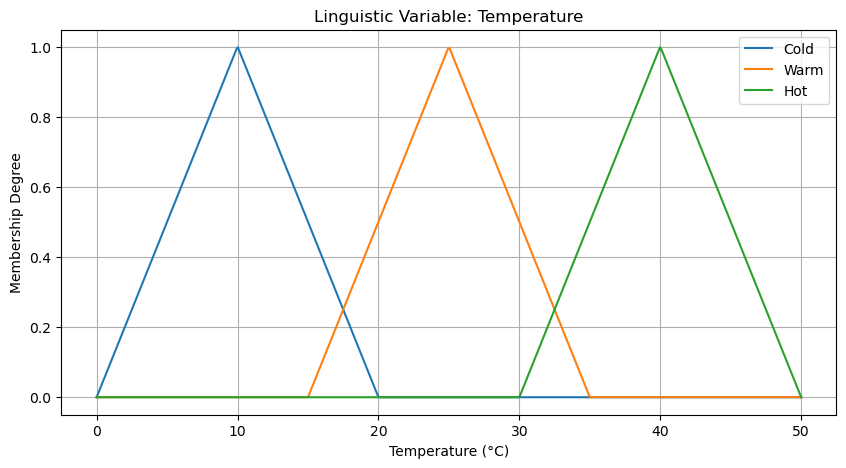

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(temperature, cold, label="Cold")
plt.plot(temperature, warm, label="Warm")
plt.plot(temperature, hot, label="Hot")

plt.xlabel("Temperature (°C)")
plt.ylabel("Membership Degree")
plt.title("Linguistic Variable: Temperature")
plt.legend()
plt.grid()
plt.show()

In [27]:
A = np.array([0.2, 0.4, 0.6, 0.8, 1.0])
B = np.array([0.8, 0.6, 0.4, 0.2, 0.1])

union = np.maximum(A, B)
intersection = np.minimum(A, B)
complement_A = 1 - A
complement_B = 1 - B

print("A:", A)
print("B:", B)
print("Union:", union)
print("Intersection:", intersection)
print("Complement A:", complement_A)
print("Complement B:", complement_B)

A: [0.2 0.4 0.6 0.8 1. ]
B: [0.8 0.6 0.4 0.2 0.1]
Union: [0.8 0.6 0.6 0.8 1. ]
Intersection: [0.2 0.4 0.4 0.2 0.1]
Complement A: [0.8 0.6 0.4 0.2 0. ]
Complement B: [0.2 0.4 0.6 0.8 0.9]


In [28]:
def fuzzy_reasoning(temp):
    cold_degree = triangular(temp, 0, 10, 20)
    warm_degree = triangular(temp, 15, 25, 35)
    hot_degree = triangular(temp, 30, 40, 50)

    if cold_degree >= warm_degree and cold_degree >= hot_degree:
        decision = "Heating Required"
    elif warm_degree >= cold_degree and warm_degree >= hot_degree:
        decision = "Maintain Temperature"
    else:
        decision = "Cooling Required"

    return cold_degree, warm_degree, hot_degree, decision

In [29]:
test_temperatures = [5, 15, 25, 35, 45]

for temp in test_temperatures:
    cold, warm, hot, decision = fuzzy_reasoning(temp)

    print(f"\nTemperature: {temp}°C")
    print(f"Cold Membership: {cold:.2f}")
    print(f"Warm Membership: {warm:.2f}")
    print(f"Hot Membership: {hot:.2f}")
    print("Decision:", decision)


Temperature: 5°C
Cold Membership: 0.50
Warm Membership: 0.00
Hot Membership: 0.00
Decision: Heating Required

Temperature: 15°C
Cold Membership: 0.50
Warm Membership: 0.00
Hot Membership: 0.00
Decision: Heating Required

Temperature: 25°C
Cold Membership: 0.00
Warm Membership: 1.00
Hot Membership: 0.00
Decision: Maintain Temperature

Temperature: 35°C
Cold Membership: 0.00
Warm Membership: 0.00
Hot Membership: 0.50
Decision: Cooling Required

Temperature: 45°C
Cold Membership: 0.00
Warm Membership: 0.00
Hot Membership: 0.50
Decision: Cooling Required


ValueError: x and y must have same first dimension, but have shapes (500,) and (1,)

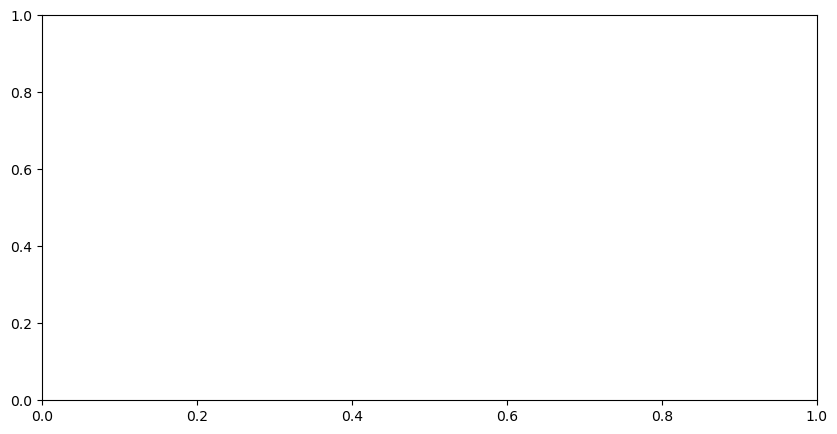

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(temperature, cold, label="Cold")
plt.plot(temperature, warm, label="Warm")
plt.plot(temperature, hot, label="Hot")

for temp in test_temperatures:
    plt.axvline(temp, linestyle="--", alpha=0.3)

plt.xlabel("Temperature (°C)")
plt.ylabel("Membership Degree")
plt.title("Fuzzy Decision-Making System")
plt.legend()
plt.grid()
plt.show()

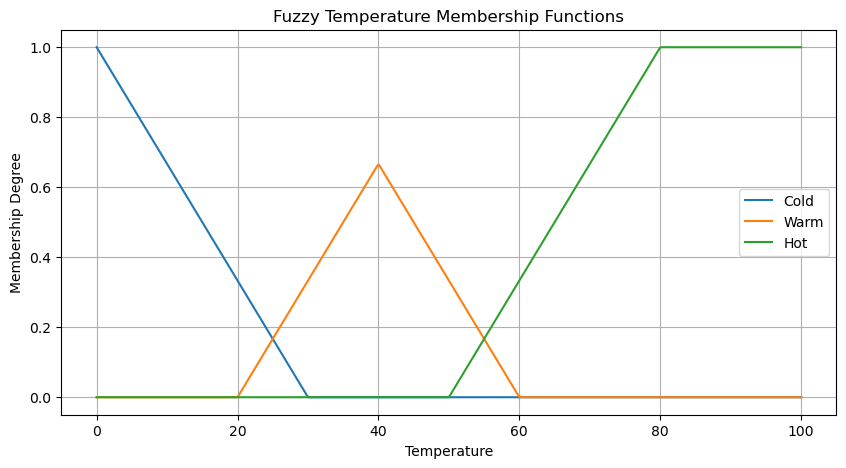

In [31]:
import numpy as np
import matplotlib.pyplot as plt

temperature = np.linspace(0, 100, 500)

# Triangular membership functions
cold = np.maximum(0, np.minimum((30 - temperature) / 30, 1))

warm = np.maximum(0, np.minimum(
    (temperature - 20) / 30,
    (60 - temperature) / 30
))

hot = np.maximum(0, np.minimum(
    (temperature - 50) / 30, 1
))

# Plot
plt.figure(figsize=(10, 5))

plt.plot(temperature, cold, label="Cold")
plt.plot(temperature, warm, label="Warm")
plt.plot(temperature, hot, label="Hot")

plt.xlabel("Temperature")
plt.ylabel("Membership Degree")
plt.title("Fuzzy Temperature Membership Functions")

plt.legend()
plt.grid()
plt.show()

## Practical - 05 Implementation of Multiple Linear Regression using multiple features and evaluation using MAE,
MSE, RMSE, and R-squared score.

In [32]:
%pip install scikit-fuzzy

   ---------------------------------------- 0.0/920.8 kB ? eta -:--:--
   --------------------------------------- 920.8/920.8 kB 11.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [33]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

In [34]:
temperature = ctrl.Antecedent(np.arange(0, 41, 1), 'temperature')
fan_speed = ctrl.Consequent(np.arange(0, 101, 1), 'fan_speed')

In [35]:
temperature['low'] = fuzz.trimf(temperature.universe, [0, 0, 20])
temperature['medium'] = fuzz.trimf(temperature.universe, [10, 20, 30])
temperature['high'] = fuzz.trimf(temperature.universe, [20, 40, 40])

fan_speed['slow'] = fuzz.trimf(fan_speed.universe, [0, 0, 50])
fan_speed['moderate'] = fuzz.trimf(fan_speed.universe, [25, 50, 75])
fan_speed['fast'] = fuzz.trimf(fan_speed.universe, [50, 100, 100])

C:\Users\REO\anaconda3\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


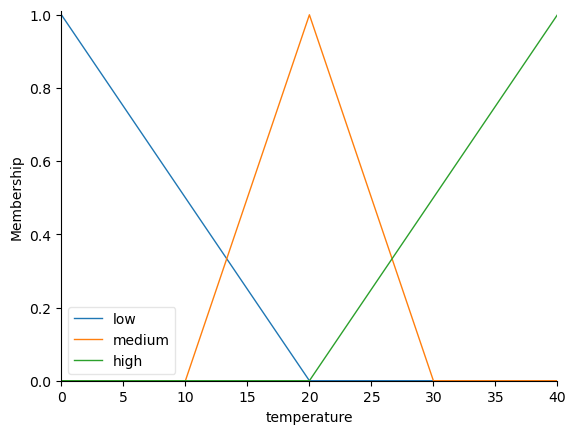

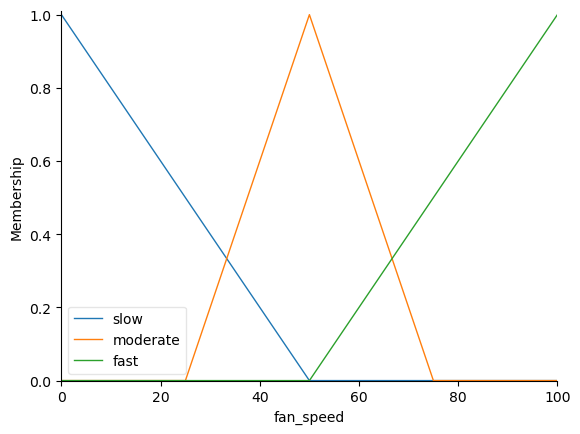

In [36]:
temperature.view()
plt.show()

fan_speed.view()
plt.show()


In [37]:
rule1 = ctrl.Rule(temperature['low'], fan_speed['slow'])
rule2 = ctrl.Rule(temperature['medium'], fan_speed['moderate'])
rule3 = ctrl.Rule(temperature['high'], fan_speed['fast'])

In [38]:
fan_control = ctrl.ControlSystem([rule1, rule2, rule3])
fan_simulation = ctrl.ControlSystemSimulation(fan_control)

In [39]:
test_temperature = 30

fan_simulation.input['temperature'] = test_temperature
fan_simulation.compute()

print("Input Temperature:", test_temperature, "°C")
print("Calculated Fan Speed:", round(fan_simulation.output['fan_speed'], 2), "%")

Input Temperature: 30 °C
Calculated Fan Speed: 80.56 %


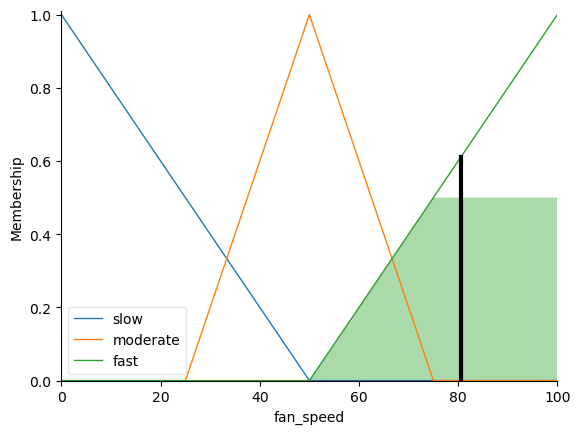

In [40]:
fan_speed.view(sim=fan_simulation)
plt.show()

In [41]:
test_values = [5, 10, 15, 20, 25, 30, 35, 40]

print("Temperature | Fan Speed")
print("------------------------")

for temp in test_values:
    simulation = ctrl.ControlSystemSimulation(fan_control)
    simulation.input['temperature'] = temp
    simulation.compute()

    speed = simulation.output['fan_speed']

    print(f"{temp:10}°C | {speed:.2f}%")

Temperature | Fan Speed
------------------------
         5°C | 17.50%
        10°C | 19.44%
        15°C | 40.21%
        20°C | 50.00%
        25°C | 59.79%
        30°C | 80.56%
        35°C | 82.50%
        40°C | 83.33%


## Practical - 06 Implementation and comparison of regularization techniques such as Ridge, Lasso, and Elastic Net
regression for improving model generalization


In [43]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

In [44]:
temperature = ctrl.Antecedent(np.arange(0, 51, 1), 'temperature')
humidity = ctrl.Antecedent(np.arange(0, 101, 1), 'humidity')

cooling = ctrl.Consequent(np.arange(0, 101, 1), 'cooling')

In [45]:
temperature['cold'] = fuzz.trimf(temperature.universe, [0, 0, 25])
temperature['comfortable'] = fuzz.trimf(temperature.universe, [15, 25, 35])
temperature['hot'] = fuzz.trimf(temperature.universe, [25, 50, 50])

humidity['low'] = fuzz.trimf(humidity.universe, [0, 0, 50])
humidity['medium'] = fuzz.trimf(humidity.universe, [25, 50, 75])
humidity['high'] = fuzz.trimf(humidity.universe, [50, 100, 100])

cooling['low'] = fuzz.trimf(cooling.universe, [0, 0, 40])
cooling['medium'] = fuzz.trimf(cooling.universe, [20, 50, 80])
cooling['high'] = fuzz.trimf(cooling.universe, [60, 100, 100])

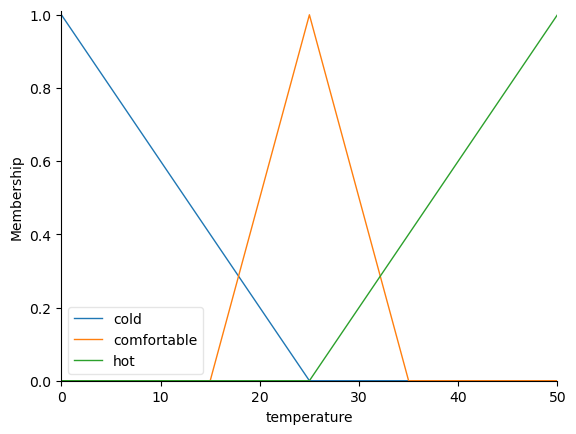

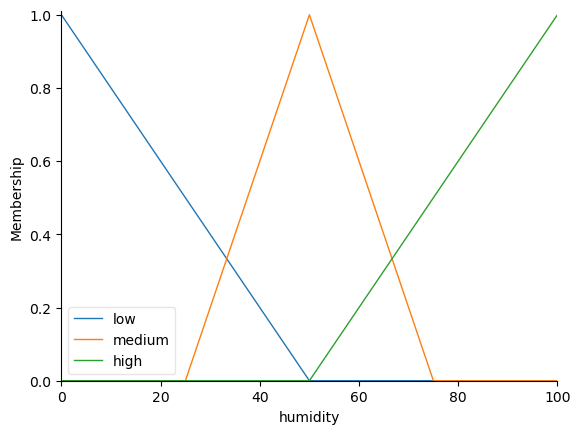

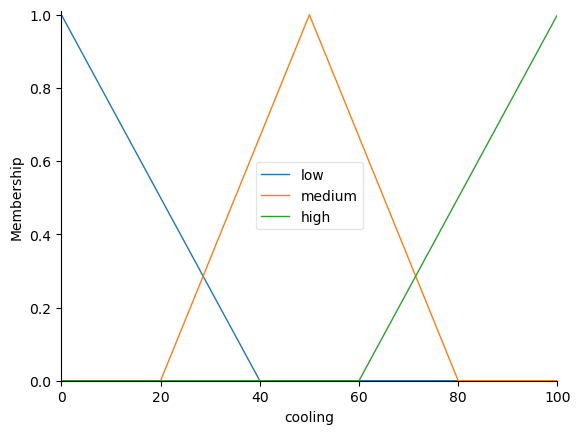

In [46]:
temperature.view()
plt.show()

humidity.view()
plt.show()

cooling.view()
plt.show()

In [47]:
rule1 = ctrl.Rule(temperature['cold'], cooling['low'])

rule2 = ctrl.Rule(
    temperature['comfortable'] & humidity['low'],
    cooling['low']
)

rule3 = ctrl.Rule(
    temperature['comfortable'] & humidity['medium'],
    cooling['medium']
)

rule4 = ctrl.Rule(
    temperature['comfortable'] & humidity['high'],
    cooling['medium']
)

rule5 = ctrl.Rule(
    temperature['hot'] & humidity['low'],
    cooling['medium']
)

rule6 = ctrl.Rule(
    temperature['hot'] & humidity['medium'],
    cooling['high']
)

rule7 = ctrl.Rule(
    temperature['hot'] & humidity['high'],
    cooling['high']
)

In [48]:
ac_control = ctrl.ControlSystem([
    rule1, rule2, rule3, rule4,
    rule5, rule6, rule7
])

ac_simulation = ctrl.ControlSystemSimulation(ac_control)

In [49]:
current_temperature = 38
current_humidity = 80

ac_simulation.input['temperature'] = current_temperature
ac_simulation.input['humidity'] = current_humidity

ac_simulation.compute()

cooling_level = ac_simulation.output['cooling']

print("Temperature:", current_temperature, "°C")
print("Humidity:", current_humidity, "%")
print("Cooling Level:", round(cooling_level, 2), "%")

if cooling_level < 30:
    print("AC Status: Low Cooling")
elif cooling_level < 70:
    print("AC Status: Medium Cooling")
else:
    print("AC Status: High Cooling")

Temperature: 38 °C
Humidity: 80 %
Cooling Level: 84.59 %
AC Status: High Cooling


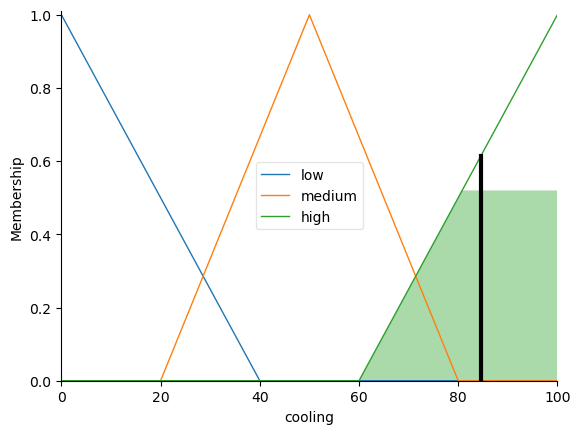

In [50]:
cooling.view(sim=ac_simulation)
plt.show()

In [51]:
test_cases = [
    (10, 30),
    (20, 40),
    (25, 60),
    (30, 70),
    (35, 80),
    (40, 90)
]

print("Temperature | Humidity | Cooling Level")
print("----------------------------------------")

for temp, hum in test_cases:
    simulation = ctrl.ControlSystemSimulation(ac_control)

    simulation.input['temperature'] = temp
    simulation.input['humidity'] = hum

    simulation.compute()

    result = simulation.output['cooling']

    print(f"{temp:10}°C | {hum:7}% | {result:.2f}%")

Temperature | Humidity | Cooling Level
----------------------------------------
        10°C |      30% | 14.86%
        20°C |      40% | 43.48%
        25°C |      60% | 50.00%
        30°C |      70% | 57.43%
        35°C |      80% | 83.67%
        40°C |      90% | 85.14%


## Practical - 07 Implementation of Logistic Regression for binary classification and performance evaluation using
confusion matrix and accuracy score.

In [52]:
import numpy as np
import matplotlib.pyplot as plt

In [53]:
def step_function(x):
    return np.where(x >= 0, 1, 0)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

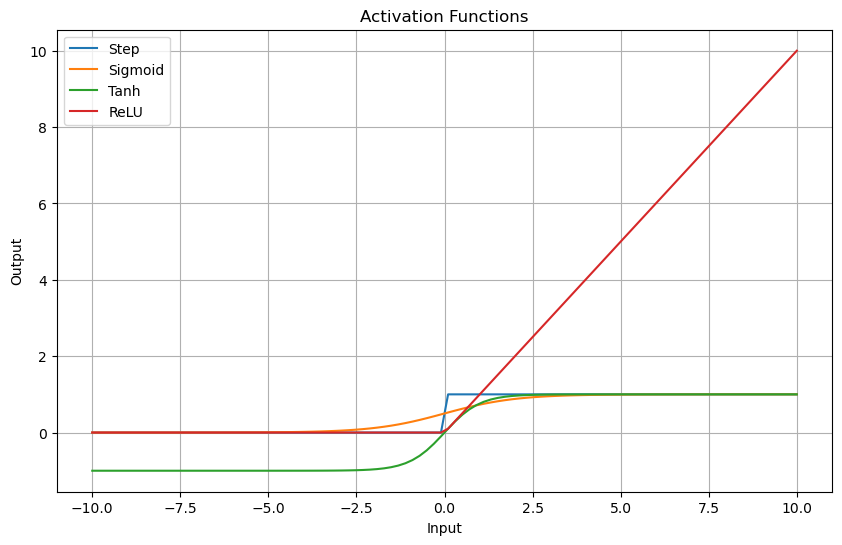

In [54]:
x = np.linspace(-10, 10, 100)

plt.figure(figsize=(10, 6))

plt.plot(x, step_function(x), label="Step")
plt.plot(x, sigmoid(x), label="Sigmoid")
plt.plot(x, tanh(x), label="Tanh")
plt.plot(x, relu(x), label="ReLU")

plt.xlabel("Input")
plt.ylabel("Output")
plt.title("Activation Functions")
plt.legend()
plt.grid()
plt.show()

In [55]:
class Perceptron:
    def __init__(self, learning_rate=0.1, epochs=10):
        self.lr = learning_rate
        self.epochs = epochs

    def fit(self, X, y):
        self.weights = np.zeros(X.shape[1])
        self.bias = 0

        for epoch in range(self.epochs):
            for i in range(len(X)):
                linear_output = np.dot(X[i], self.weights) + self.bias
                prediction = step_function(linear_output)

                error = y[i] - prediction

                self.weights += self.lr * error * X[i]
                self.bias += self.lr * error

    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return step_function(linear_output)

In [56]:
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([0, 0, 0, 1])

In [57]:
model = Perceptron(learning_rate=0.1, epochs=10)

model.fit(X, y)

print("Weights:", model.weights)
print("Bias:", model.bias)

Weights: [0.2 0.1]
Bias: -0.20000000000000004


In [58]:
predictions = model.predict(X)

print("Input | Actual | Predicted")
print("---------------------------")

for i in range(len(X)):
    print(X[i], " | ", y[i], " | ", predictions[i])

Input | Actual | Predicted
---------------------------
[0 0]  |  0  |  0
[0 1]  |  0  |  0
[1 0]  |  0  |  0
[1 1]  |  1  |  1


In [59]:
test_data = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

results = model.predict(test_data)

for inputs, output in zip(test_data, results):
    print(f"Input: {inputs} -> Output: {output}")

Input: [0 0] -> Output: 0
Input: [0 1] -> Output: 0
Input: [1 0] -> Output: 0
Input: [1 1] -> Output: 1


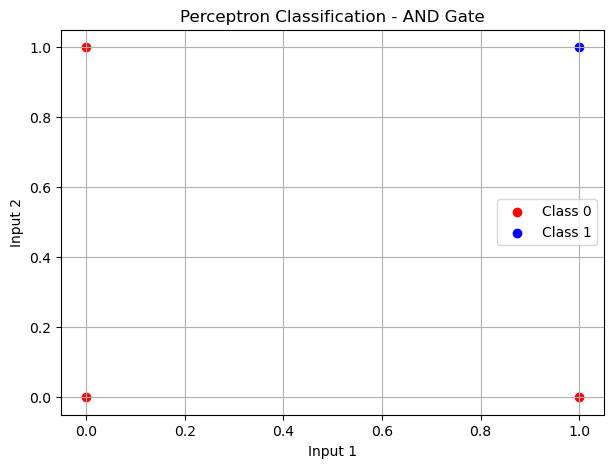

In [60]:
plt.figure(figsize=(7, 5))

for i in range(len(X)):
    if y[i] == 0:
        plt.scatter(X[i, 0], X[i, 1], color='red', label='Class 0' if i == 0 else "")
    else:
        plt.scatter(X[i, 0], X[i, 1], color='blue', label='Class 1')

plt.xlabel("Input 1")
plt.ylabel("Input 2")
plt.title("Perceptron Classification - AND Gate")
plt.legend()
plt.grid()
plt.show()

## Practical - 08 Implementation of the K-Nearest Neighbours (KNN) classification algorithm and analysis of the
impact of different values of K on model accuracy

In [62]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [63]:
digits = load_digits()

X = digits.data
y = digits.target

print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)
print("Number of Classes:", len(np.unique(y)))

Dataset Shape: (1797, 64)
Target Shape: (1797,)
Number of Classes: 10


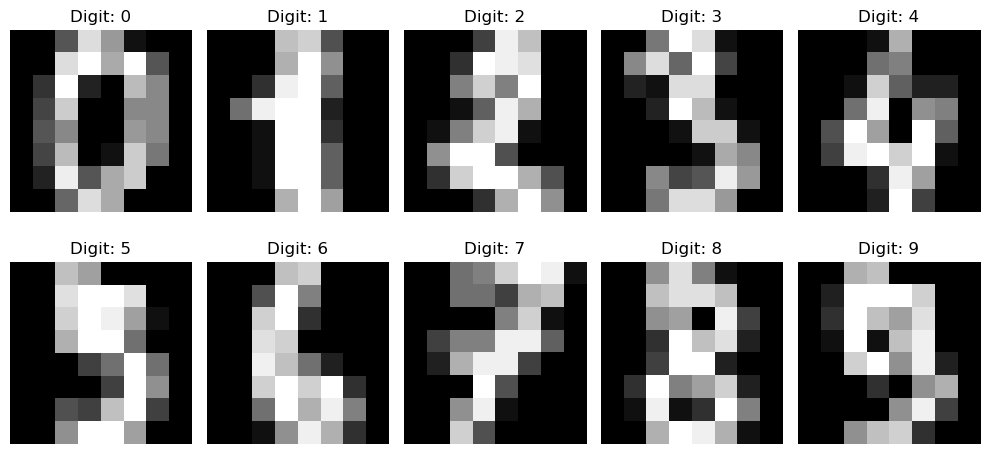

In [64]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for ax, image, label in zip(axes.ravel(), digits.images[:10], digits.target[:10]):
    ax.imshow(image, cmap='gray')
    ax.set_title(f"Digit: {label}")
    ax.axis('off')

plt.tight_layout()
plt.show()

In [65]:
X = X / 16.0

print("Normalized Data:")
print(X[0])

Normalized Data:
[0.     0.     0.3125 0.8125 0.5625 0.0625 0.     0.     0.     0.
 0.8125 0.9375 0.625  0.9375 0.3125 0.     0.     0.1875 0.9375 0.125
 0.     0.6875 0.5    0.     0.     0.25   0.75   0.     0.     0.5
 0.5    0.     0.     0.3125 0.5    0.     0.     0.5625 0.5    0.
 0.     0.25   0.6875 0.     0.0625 0.75   0.4375 0.     0.     0.125
 0.875  0.3125 0.625  0.75   0.     0.     0.     0.     0.375  0.8125
 0.625  0.     0.     0.    ]


In [66]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 1437
Testing Samples: 360


In [67]:
model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=500,
    random_state=42
)

In [68]:
model.fit(X_train, y_train)

print("Neural Network Training Completed")

Neural Network Training Completed


In [69]:
y_pred = model.predict(X_test)

print("Actual Labels:   ", y_test[:20])
print("Predicted Labels:", y_pred[:20])

Actual Labels:    [5 2 8 1 7 2 6 2 6 5 0 5 9 3 4 4 2 4 9 9]
Predicted Labels: [5 2 8 1 7 2 6 2 6 5 0 5 9 3 4 4 2 4 9 9]


In [70]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 97.78 %


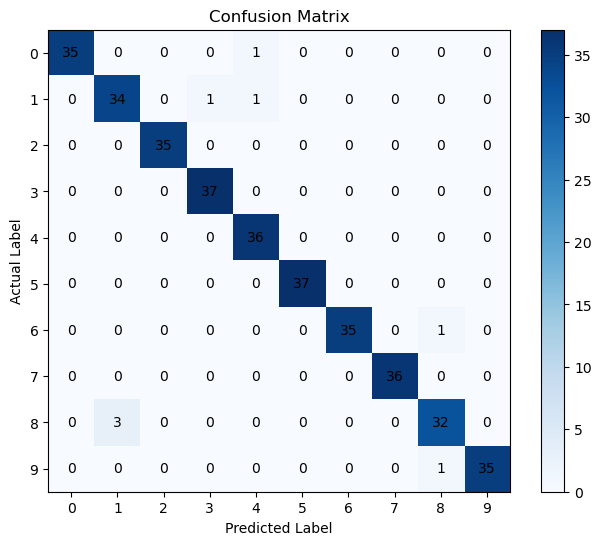

In [71]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.colorbar()

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.xticks(range(10))
plt.yticks(range(10))
plt.show()

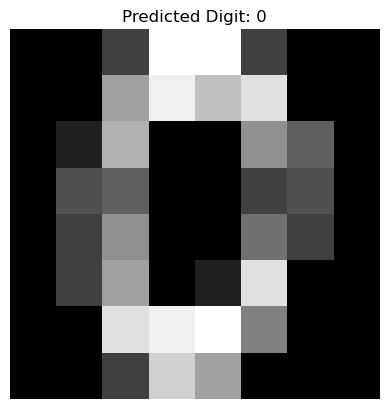

Predicted Digit: 0
Actual Digit: 0


In [72]:
index = 10

sample = X_test[index].reshape(1, -1)
prediction = model.predict(sample)

plt.imshow(X_test[index].reshape(8, 8), cmap='gray')
plt.title(f"Predicted Digit: {prediction[0]}")
plt.axis('off')
plt.show()

print("Predicted Digit:", prediction[0])
print("Actual Digit:", y_test[index])

## Practical - 09 Implementation of a Decision Tree Classifier and study of the effect of tree depth on classification
performance

In [74]:
import random
import matplotlib.pyplot as plt

random.seed(42)

In [75]:
def fitness(x):
    return x ** 2

In [76]:
population_size = 10
population = [random.randint(0, 31) for _ in range(population_size)]

print("Initial Population:")
print(population)

Initial Population:
[7, 1, 17, 15, 14, 8, 6, 5, 27, 2]


In [77]:
def to_binary(n):
    return format(n, '05b')

for individual in population:
    print(individual, "->", to_binary(individual))

7 -> 00111
1 -> 00001
17 -> 10001
15 -> 01111
14 -> 01110
8 -> 01000
6 -> 00110
5 -> 00101
27 -> 11011
2 -> 00010


In [78]:
def selection(population):
    selected = sorted(population, key=fitness, reverse=True)
    return selected[:2]

parents = selection(population)

print("Selected Parents:", parents)

Selected Parents: [27, 17]


In [79]:
def crossover(parent1, parent2):
    p1 = to_binary(parent1)
    p2 = to_binary(parent2)

    point = random.randint(1, 4)

    child1 = p1[:point] + p2[point:]
    child2 = p2[:point] + p1[point:]

    return int(child1, 2), int(child2, 2)

child1, child2 = crossover(parents[0], parents[1])

print("Parent 1:", to_binary(parents[0]))
print("Parent 2:", to_binary(parents[1]))
print("Child 1:", to_binary(child1), "=", child1)
print("Child 2:", to_binary(child2), "=", child2)

Parent 1: 11011
Parent 2: 10001
Child 1: 10001 = 17
Child 2: 11011 = 27


In [80]:
def mutation(individual, mutation_rate=0.1):
    binary = list(to_binary(individual))

    for i in range(len(binary)):
        if random.random() < mutation_rate:
            binary[i] = '1' if binary[i] == '0' else '0'

    return int(''.join(binary), 2)

mutated_child1 = mutation(child1)
mutated_child2 = mutation(child2)

print("Before Mutation:", child1, child2)
print("After Mutation:", mutated_child1, mutated_child2)


Before Mutation: 17 27
After Mutation: 1 27


In [81]:
population_size = 10
generations = 30

population = [random.randint(0, 31) for _ in range(population_size)]

best_fitness_history = []

for generation in range(generations):

    population = sorted(population, key=fitness, reverse=True)

    best_fitness_history.append(fitness(population[0]))

    new_population = population[:2]

    while len(new_population) < population_size:

        parent1, parent2 = random.choices(population[:5], k=2)

        child1, child2 = crossover(parent1, parent2)

        child1 = mutation(child1, 0.1)
        child2 = mutation(child2, 0.1)

        new_population.append(child1)

        if len(new_population) < population_size:
            new_population.append(child2)

    population = new_population

best_solution = max(population, key=fitness)

print("Best Solution:", best_solution)
print("Maximum Fitness:", fitness(best_solution))

Best Solution: 31
Maximum Fitness: 961


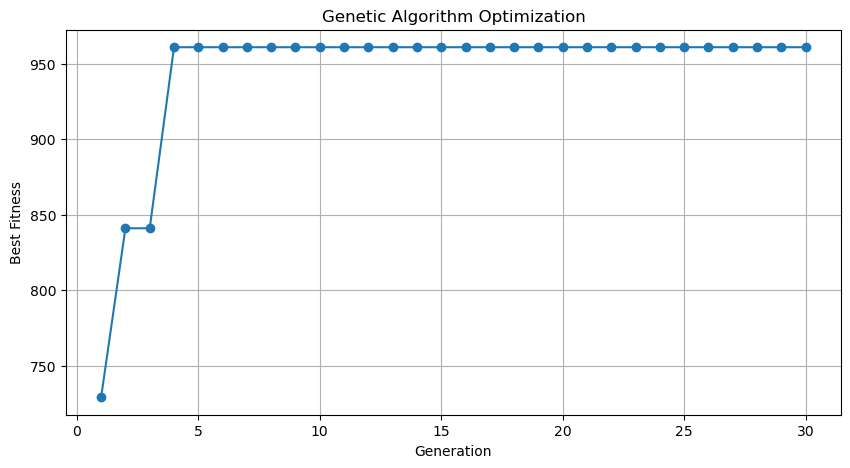

In [82]:
plt.figure(figsize=(10, 5))

plt.plot(range(1, generations + 1), best_fitness_history, marker='o')

plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.title("Genetic Algorithm Optimization")
plt.grid(True)
plt.show()

In [83]:
print("Final Population:")

for individual in population:
    print(
        "Decimal:", individual,
        "| Binary:", to_binary(individual),
        "| Fitness:", fitness(individual)
    )
    

Final Population:
Decimal: 31 | Binary: 11111 | Fitness: 961
Decimal: 31 | Binary: 11111 | Fitness: 961
Decimal: 27 | Binary: 11011 | Fitness: 729
Decimal: 31 | Binary: 11111 | Fitness: 961
Decimal: 31 | Binary: 11111 | Fitness: 961
Decimal: 31 | Binary: 11111 | Fitness: 961
Decimal: 30 | Binary: 11110 | Fitness: 900
Decimal: 31 | Binary: 11111 | Fitness: 961
Decimal: 31 | Binary: 11111 | Fitness: 961
Decimal: 31 | Binary: 11111 | Fitness: 961


## Practical - 10 Implementation of an ensemble learning model using Random Forest and comparison with
Decision Tree classifier.


In [1]:
# Step 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [2]:
# Step 2: Load the dataset

iris = load_iris()

X = iris.data
y = iris.target

print("Dataset Features:")
print(iris.feature_names)

print("\nTarget Classes:")
print(iris.target_names)

print("\nDataset Shape:", X.shape)

Dataset Features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target Classes:
['setosa' 'versicolor' 'virginica']

Dataset Shape: (150, 4)


In [3]:
# Step 3: Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [4]:
# Step 4: Implement Decision Tree Classifier

dt_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 1.0


In [5]:
# Step 5: Implement Random Forest Classifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 1.0


In [6]:
# Step 6: Compare model performance

results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Accuracy': [dt_accuracy, rf_accuracy]
})

print(results)

           Model  Accuracy
0  Decision Tree       1.0
1  Random Forest       1.0


In [7]:
# Step 7: Display classification reports

print("Decision Tree Classification Report")
print(classification_report(
    y_test,
    dt_predictions,
    target_names=iris.target_names
))

print("\nRandom Forest Classification Report")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=iris.target_names
))

Decision Tree Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


Random Forest Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



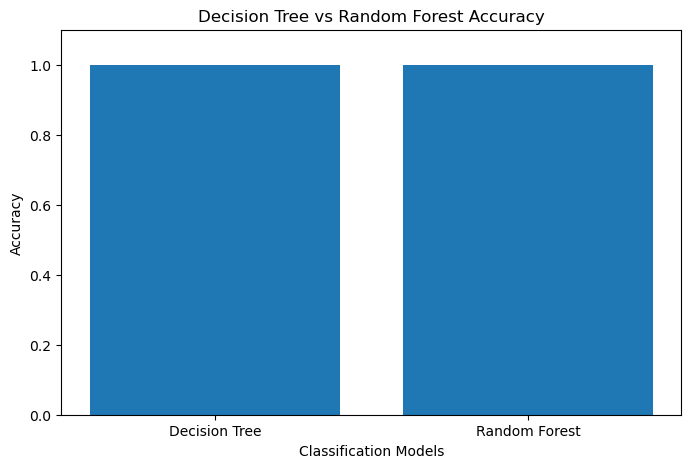

In [8]:
# Step 8: Visualize accuracy comparison

plt.figure(figsize=(8, 5))

plt.bar(
    results['Model'],
    results['Accuracy']
)

plt.xlabel("Classification Models")
plt.ylabel("Accuracy")
plt.title("Decision Tree vs Random Forest Accuracy")

plt.ylim(0, 1.1)
plt.show()

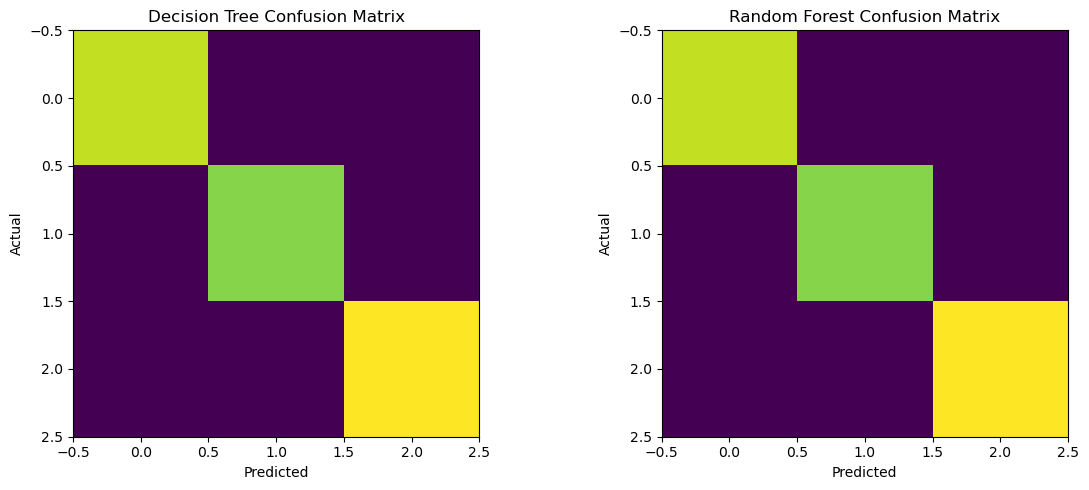

In [9]:
# Step 9: Display confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Decision Tree
axes[0].imshow(confusion_matrix(y_test, dt_predictions))
axes[0].set_title("Decision Tree Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Random Forest
axes[1].imshow(confusion_matrix(y_test, rf_predictions))
axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

## Practical 11 Implementation of K-Means clustering on an unlabelled dataset and determination of the optimal
number of clusters using the Elbow method.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [11]:
# Generate sample dataset

X, y = make_blobs(
    n_samples=300,
    centers=4,
    cluster_std=0.60,
    random_state=42
)

# Convert into DataFrame

df = pd.DataFrame(X, columns=['Feature1', 'Feature2'])

print(df.head())
print("Dataset Shape:", df.shape)

    Feature1  Feature2
0  -9.113944  6.813616
1  -9.354576  7.092790
2  -2.015671  8.281780
3  -7.010236 -6.220843
4 -10.061202  6.718671
Dataset Shape: (300, 2)


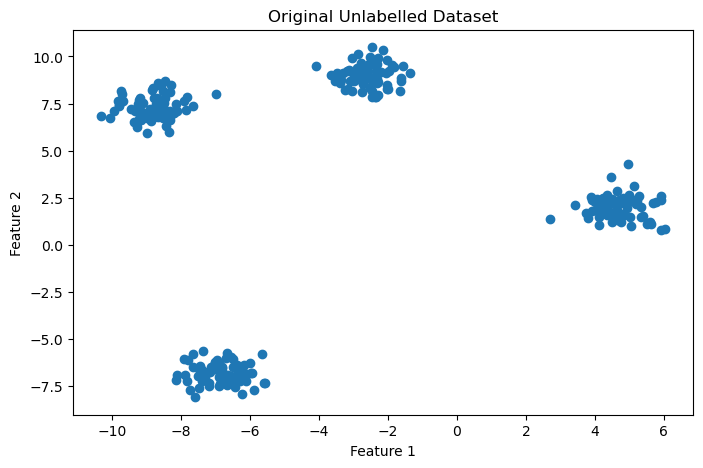

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Feature1'],
    df['Feature2']
)

plt.title("Original Unlabelled Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [13]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

C:\Users\REO\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\REO\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\REO\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\REO\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^

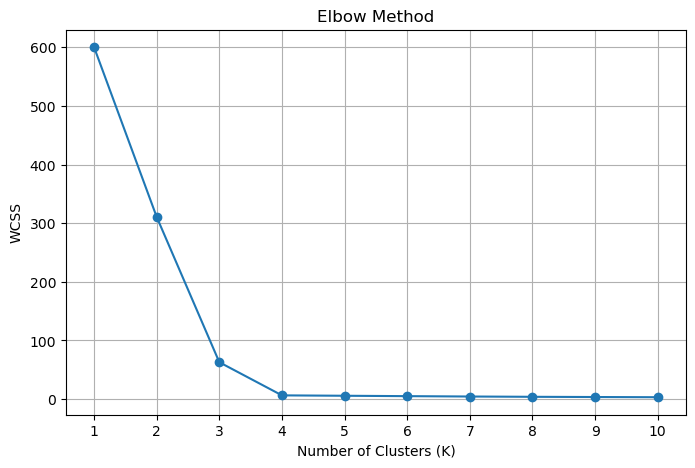

In [14]:
wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

# Plot Elbow Graph

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [15]:
# Optimal number of clusters

k = 4

kmeans = KMeans(
    n_clusters=k,
    init='k-means++',
    random_state=42,
    n_init=10
)

y_kmeans = kmeans.fit_predict(X_scaled)

df['Cluster'] = y_kmeans

print(df.head())

    Feature1  Feature2  Cluster
0  -9.113944  6.813616        3
1  -9.354576  7.092790        3
2  -2.015671  8.281780        0
3  -7.010236 -6.220843        1
4 -10.061202  6.718671        3


C:\Users\REO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


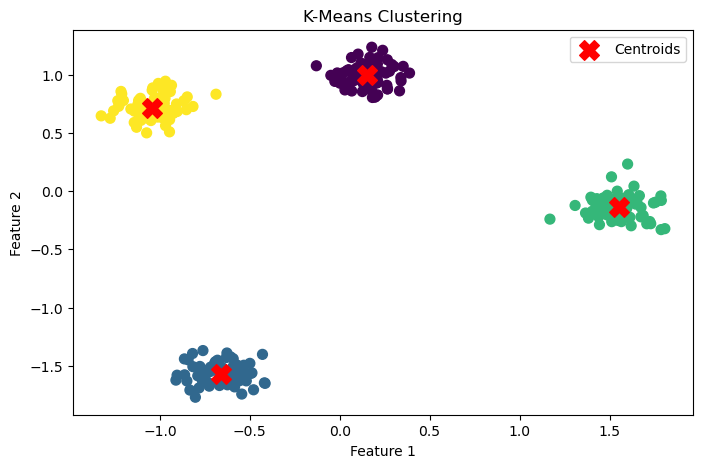

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y_kmeans,
    cmap='viridis',
    s=50
)

# Plot cluster centroids

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Centroids'
)

plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()

plt.show()

In [17]:
print("Number of Clusters:", k)

print("\nCluster Distribution:")
print(df['Cluster'].value_counts())

print("\nCluster Centroids:")
print(kmeans.cluster_centers_)

Number of Clusters: 4

Cluster Distribution:
Cluster
3    75
0    75
1    75
2    75
Name: count, dtype: int64

Cluster Centroids:
[[ 0.15256919  0.99257342]
 [-0.66142128 -1.56752677]
 [ 1.55047856 -0.13507979]
 [-1.04162647  0.71003314]]


## Practical 12 Implementation of Hierarchical Clustering using the agglomerative approach and visualization of
clusters using dendrograms.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler

from scipy.cluster.hierarchy import dendrogram, linkage

In [20]:
# Generate sample dataset

X, y = make_blobs(
    n_samples=100,
    centers=3,
    cluster_std=1.0,
    random_state=42
)

df = pd.DataFrame(X, columns=['Feature1', 'Feature2'])

print(df.head())
print("Dataset Shape:", df.shape)

   Feature1  Feature2
0 -7.726421 -8.394957
1  5.453396  0.742305
2 -2.978672  9.556846
3  6.042673  0.571319
4 -6.521840 -6.319325
Dataset Shape: (100, 2)


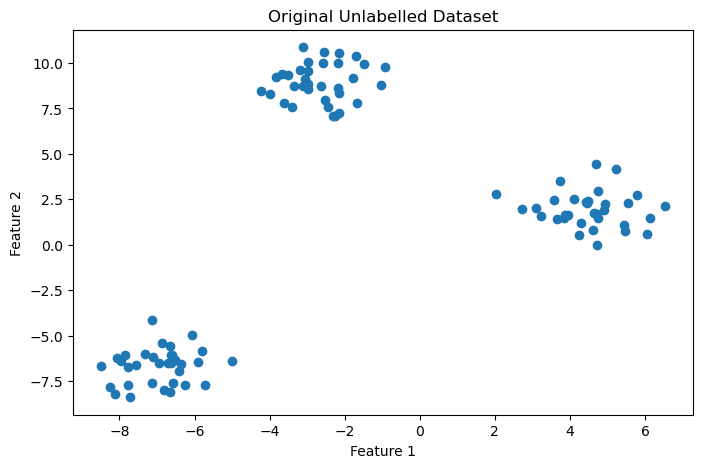

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(X[:, 0], X[:, 1])

plt.title("Original Unlabelled Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [22]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

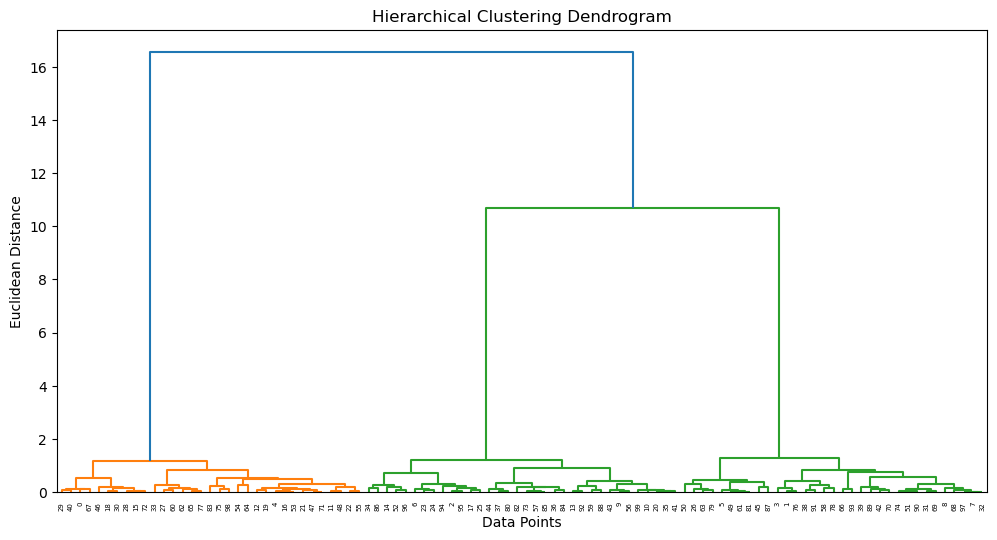

In [23]:
# Calculate linkage matrix

linked = linkage(
    X_scaled,
    method='ward'
)

# Plot dendrogram

plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")

plt.show()

In [24]:
model = AgglomerativeClustering(
    n_clusters=3,
    metric='euclidean',
    linkage='ward'
)

clusters = model.fit_predict(X_scaled)

df['Cluster'] = clusters

print(df.head())

   Feature1  Feature2  Cluster
0 -7.726421 -8.394957        1
1  5.453396  0.742305        0
2 -2.978672  9.556846        2
3  6.042673  0.571319        0
4 -6.521840 -6.319325        1


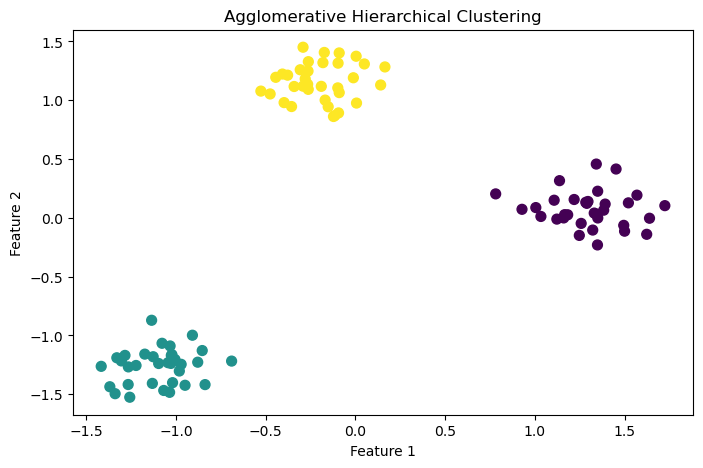

In [25]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    s=50
)

plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [26]:
print("Number of Clusters:", len(np.unique(clusters)))

print("\nCluster Distribution:")
print(df['Cluster'].value_counts())

Number of Clusters: 3

Cluster Distribution:
Cluster
2    34
1    33
0    33
Name: count, dtype: int64


## Practical 13 Implementation of DBSCAN clustering for identification of clusters and detection of outliers in a
dataset

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

In [29]:
# Generate sample dataset

X, y = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=0.60,
    random_state=42
)

# Add some random outliers

rng = np.random.RandomState(42)

outliers = rng.uniform(
    low=-10,
    high=10,
    size=(20, 2)
)

X = np.vstack((X, outliers))

df = pd.DataFrame(
    X,
    columns=['Feature1', 'Feature2']
)

print(df.head())
print("Dataset Shape:", df.shape)

   Feature1  Feature2
0 -7.155244 -7.390016
1 -7.395875 -7.110843
2 -2.015671  8.281780
3  4.509270  2.632436
4 -8.102502 -7.484961
Dataset Shape: (320, 2)


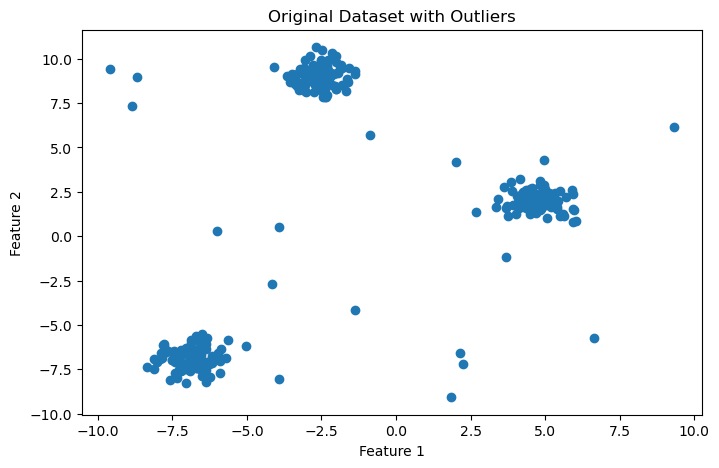

In [30]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1]
)

plt.title("Original Dataset with Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [31]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [32]:
dbscan = DBSCAN(
    eps=0.25,
    min_samples=5
)

clusters = dbscan.fit_predict(X_scaled)

df['Cluster'] = clusters

print(df.head())

   Feature1  Feature2  Cluster
0 -7.155244 -7.390016        0
1 -7.395875 -7.110843        0
2 -2.015671  8.281780        1
3  4.509270  2.632436        2
4 -8.102502 -7.484961        0


In [33]:
# Count number of clusters (excluding noise label -1)

n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)

# Count outliers

n_outliers = list(clusters).count(-1)

print("Number of Clusters:", n_clusters)

print("Number of Outliers:", n_outliers)

print("\nCluster Distribution:")
print(df['Cluster'].value_counts())

Number of Clusters: 3
Number of Outliers: 16

Cluster Distribution:
Cluster
 0    102
 1    101
 2    101
-1     16
Name: count, dtype: int64


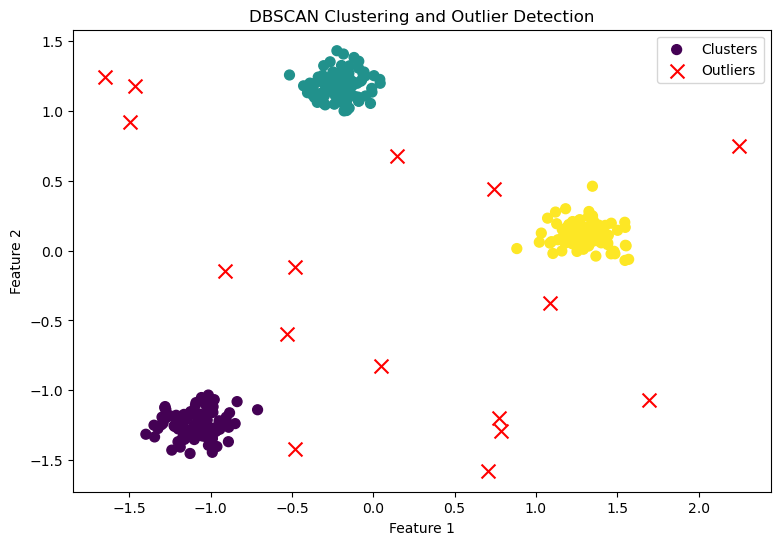

In [34]:
plt.figure(figsize=(9, 6))

# Plot all clusters

plt.scatter(
    X_scaled[clusters != -1, 0],
    X_scaled[clusters != -1, 1],
    c=clusters[clusters != -1],
    cmap='viridis',
    s=50,
    label='Clusters'
)

# Plot outliers in red

plt.scatter(
    X_scaled[clusters == -1, 0],
    X_scaled[clusters == -1, 1],
    color='red',
    marker='x',
    s=100,
    label='Outliers'
)

plt.title("DBSCAN Clustering and Outlier Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()

plt.show()

In [35]:
outlier_data = df[df['Cluster'] == -1]

print("Detected Outliers:")
print(outlier_data)

print("\nTotal Outliers:", len(outlier_data))

Detected Outliers:
     Feature1  Feature2  Cluster
303 -8.838328  7.323523       -1
304  2.022300  4.161452       -1
305 -9.588310  9.398197       -1
306  6.648853 -5.753218       -1
308 -3.915155  0.495129       -1
309 -1.361100 -4.175417       -1
310  2.237058 -7.210123       -1
311 -4.157107 -2.672763       -1
312 -0.878600  5.703519       -1
313 -6.006524  0.284689       -1
314  1.848291 -9.070992       -1
315  2.150897 -6.589518       -1
316 -8.698968  8.977711       -1
317  9.312641  6.167947       -1
318 -3.907725 -8.046558       -1
319  3.684661 -1.196950       -1

Total Outliers: 16


## Practical 14 Application of Principal Component Analysis (PCA) for dimensionality reduction and analysis of
variance preservation.

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [37]:
# Load Iris dataset

iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

print("Original Dataset:")
print(df.head())

print("\nDataset Shape:", X.shape)

Original Dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset Shape: (150, 4)


In [38]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardized Dataset:")
print(X_scaled[:5])

Standardized Dataset:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [39]:
# Reduce dimensions from 4 to 2

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Reduced Dataset:")
print(X_pca[:5])

print("\nOriginal Shape:", X.shape)
print("Reduced Shape:", X_pca.shape)

Reduced Dataset:
[[-2.26470281  0.4800266 ]
 [-2.08096115 -0.67413356]
 [-2.36422905 -0.34190802]
 [-2.29938422 -0.59739451]
 [-2.38984217  0.64683538]]

Original Shape: (150, 4)
Reduced Shape: (150, 2)


In [40]:
explained_variance = pca.explained_variance_ratio_

print("Explained Variance Ratio:")
print(explained_variance)

print("\nTotal Variance Preserved:",
      sum(explained_variance) * 100, "%")

Explained Variance Ratio:
[0.72962445 0.22850762]

Total Variance Preserved: 95.81320720000164 %


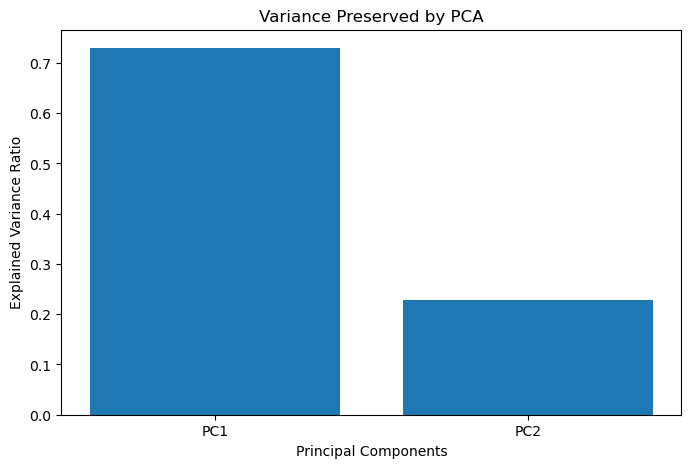

In [41]:
plt.figure(figsize=(8, 5))

plt.bar(
    ['PC1', 'PC2'],
    explained_variance
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("Variance Preserved by PCA")

plt.show()

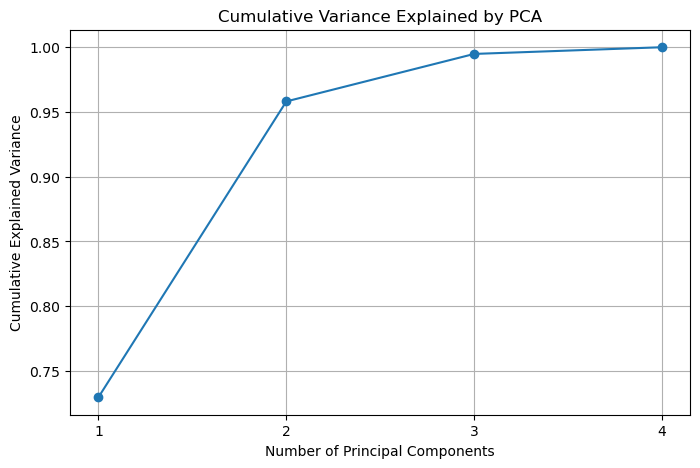

In [42]:
pca_full = PCA()

pca_full.fit(X_scaled)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Variance Explained by PCA")

plt.xticks(range(1, 5))
plt.grid(True)

plt.show()

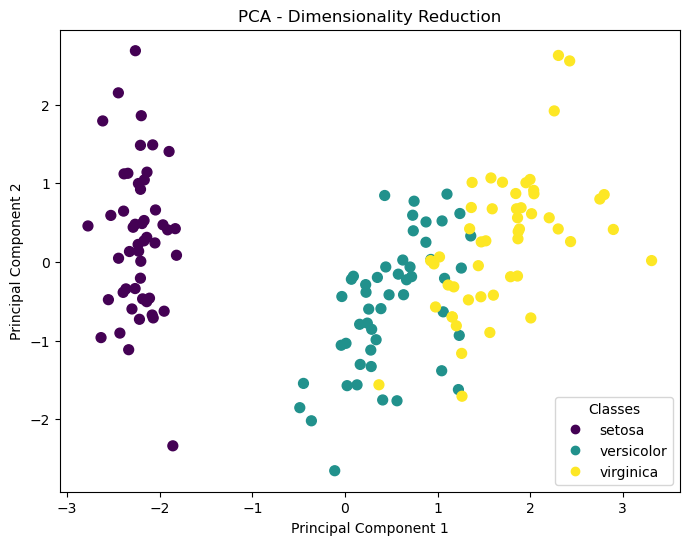

In [43]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap='viridis',
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA - Dimensionality Reduction")

plt.legend(
    handles=scatter.legend_elements()[0],
    labels=list(iris.target_names),
    title="Classes"
)

plt.show()

In [44]:
print("Original Number of Features:", X.shape[1])

print("Reduced Number of Features:", X_pca.shape[1])

print("Variance Preserved:",
      round(sum(explained_variance) * 100, 2), "%")

print("Variance Lost:",
      round((1 - sum(explained_variance)) * 100, 2), "%")

Original Number of Features: 4
Reduced Number of Features: 2
Variance Preserved: 95.81 %
Variance Lost: 4.19 %


## Practical 15 Performance of hyperparameter tuning using Grid Search and Cross-Validation for improving
machine learning model performance

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score, classification_report

In [47]:
# Load Iris dataset

iris = load_iris()

X = iris.data
y = iris.target

print("Dataset Shape:", X.shape)
print("Target Classes:", iris.target_names)

Dataset Shape: (150, 4)
Target Classes: ['setosa' 'versicolor' 'virginica']


In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


In [49]:
# Create Decision Tree model

dt_model = DecisionTreeClassifier(random_state=42)

# Train model

dt_model.fit(X_train, y_train)

# Make predictions

y_pred = dt_model.predict(X_test)

# Calculate accuracy

basic_accuracy = accuracy_score(y_test, y_pred)

print("Accuracy Before Tuning:", basic_accuracy)

Accuracy Before Tuning: 0.9333333333333333


In [50]:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 3, 4, 5, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

print(param_grid)

{'criterion': ['gini', 'entropy'], 'max_depth': [2, 3, 4, 5, None], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]}


In [51]:
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Train Grid Search

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(grid_search.best_score_)

Best Parameters:
{'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}

Best Cross-Validation Accuracy:
0.9416666666666668


In [52]:
best_model = grid_search.best_estimator_

# Predict test data

y_pred_best = best_model.predict(X_test)

# Calculate accuracy

tuned_accuracy = accuracy_score(y_test, y_pred_best)

print("Accuracy After Tuning:", tuned_accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_best,
    target_names=iris.target_names
))

Accuracy After Tuning: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [53]:
results = pd.DataFrame({
    'Model': ['Before Tuning', 'After Tuning'],
    'Accuracy': [basic_accuracy, tuned_accuracy]
})

print(results)

           Model  Accuracy
0  Before Tuning  0.933333
1   After Tuning  0.933333


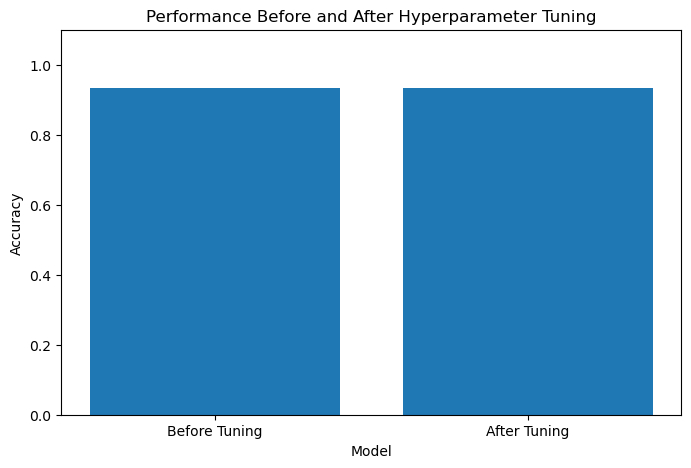

In [54]:
plt.figure(figsize=(8, 5))

plt.bar(
    results['Model'],
    results['Accuracy']
)

plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Performance Before and After Hyperparameter Tuning")

plt.ylim(0, 1.1)
plt.show()

In [55]:
print("Best Model:", best_model)

print("\nBest Parameters:")
for parameter, value in grid_search.best_params_.items():
    print(parameter, ":", value)

print("\nBest Test Accuracy:", tuned_accuracy)

Best Model: DecisionTreeClassifier(max_depth=4, random_state=42)

Best Parameters:
criterion : gini
max_depth : 4
min_samples_leaf : 1
min_samples_split : 2

Best Test Accuracy: 0.9333333333333333
